# Project

In this project we will investigate the method of Physical Informed Weak Regression PIWR. The worked case is the Smallpox model

In [56]:
import importlib
import functions

print(functions.__file__)  # confirm the file path
importlib.invalidate_caches()
importlib.reload(functions)

print(hasattr(functions, "smallpox_theta"))
from functions import smallpox_theta

/Users/dittejuhler-nottrup/Documents/GitHub/data_driven/Project/functions.py
True


In [57]:
# Import relevant parameters
import numpy as np
from scipy.integrate import solve_ivp, quad
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline

# Import own functions
from functions import *

np.set_printoptions(legacy = '1.25')

This code focuses on the Smallpox model

### INSERT SMALLPOX MODEL IN MATH MODE HERE

In [58]:
# Define the Smallpox model
def smallpox_model(t, x, p):
    # p = [Chi1, Chi2, epsilon1, epsilon2, rho, theta, alfa, gamma]
    # x = states [S, En, Ei, Ci, I, Q, U, V]
    
    Chi1, Chi2, epsilon1, epsilon2, rho, theta, alfa, gamma, N = p
        
    S, En, Ei, Ci, I, Q, U, V = x
    
    phi = I/S
    beta = 10 * gamma /(phi * N)
    
    
    dS = Chi1 * (1 - epsilon1) * Ci - beta * (phi + rho - phi * rho) * S * I
    dEn = beta * phi * (1 - rho) * S * I - alfa * En
    dEi = beta * phi * rho * S * I - (Chi1 * epsilon2 + alfa * (1 - epsilon2)) * Ei
    dCi = beta * rho * (1 - phi) * S * I - Chi1 * Ci
    dI = alfa * (1 - theta) * En - (theta + gamma) * I
    dQ = alfa * (1 - epsilon2) * Ei + theta * (alfa * En + I) - Chi2 * Q
    dU = gamma * I + Chi2 * Q
    dV = Chi1 * (epsilon2 * Ei + epsilon1 * Ci)
    
    dxdt = np.array([dS, dEn, dEi, dCi, dI, dQ, dU, dV])

    return dxdt

In [59]:
""" Define interval and parameters for testing """

# The model is tested on 50 data points over 10 years.
t0 = 0
tf = 100 # Days
tspan = [t0, tf]
m = 50 # Samples
t = np.linspace(t0, tf, m)

# parameters from article used
N = 7100 # Population size
par = [0.06, 0.04, 0.975, 0.3, 0.975, 0.95, 0.0685, 0.116, N]
omega = par[:-1]
k = len(omega)

# S, En, Ei, Ci, I, Q, U, V
x0 = [7000, 0, 0, 0, 100, 0, 0, 0]
n = len(x0)

test = smallpox_model(t, x0, par)

sol = solve_ivp(smallpox_model, tspan, x0, method = "BDF", t_eval = t, args = (par,))

S, En, Ei, Ci, I, Q, U, V = sol.y
t = sol.t
y = sol.y


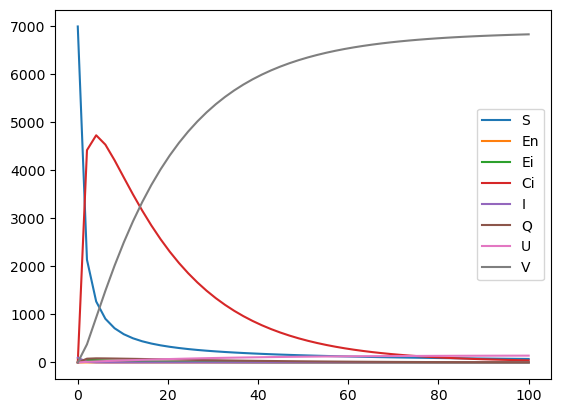

In [60]:
# Plot solution
plt.plot(t, S, label = "S")
plt.plot(t, En, label = "En")
plt.plot(t, Ei, label = "Ei")
plt.plot(t, Ci, label = "Ci")
plt.plot(t, I, label = "I")
plt.plot(t, Q, label = "Q")
plt.plot(t, U, label = "U")
plt.plot(t, V, label = "V")
plt.legend()
plt.show()

The model is now written as a function of the parameters, instead of t. A linear model should be obtain, to support the regression. Therefore a new parameter vector is constructed, $\boldsymbol{\theta}$, containing the parameters, which construct a linear model of the form:

$\boldsymbol{\dot{x}} = f_0(\boldsymbol{x}, t) + \mathbf{A}(\boldsymbol{x},t)\boldsymbol{\theta}$

For the smallpox model $\boldsymbol{\theta}$ is given by:

### INSERT THETA

To convert $\boldsymbol{\theta}$ back to the original parameters, $\boldsymbol{\omega}$, a function $h(\boldsymbol{\theta})$, is created:

### DESCRIBE THE FUNCTION h

The matrix \mathbf{A}(\boldsymbol{x},t) is created for the smallpox model as:

### INSERT A IN MATH

The functions for $\boldsymbol{\theta}$, h and A can be seen in ...


In [61]:
def smallpox_theta(par):
    return np.array([par[0], par[0]*par[2], par[7], par[7]*par[4], par[6],
                     par[0]*par[3], par[6]*par[3], par[5], par[6]*par[5], par[1]])
# Creating a function h that takes theta and returns omega: w = h(theta)
def smallpox_h(theta):
    omega = np.array([theta[0], theta[9], theta[1]/theta[0], theta[5]/theta[0], theta[3]/theta[2], theta[7], theta[4], theta[2]])
    return omega

# Linear system matrix
def smallpox_A(y, N):
    S, En, Ei, Ci, I, Q, U, V = y
    A = np.array([[Ci, -Ci, -10 * S * I / N, 10 * S * I / N - 10 * S**2 / N, 0, 0, 0, 0, 0, 0],
                    [0, 0, 10*S*I/N, -10*S*I/N, -En, 0, 0, 0, 0, 0],
                    [0, 0, 0, 10*S*I/N, -Ei, -Ei, Ei, 0, 0, 0],
                    [-Ci, 0, 0, 10*S**2/N - 10*S*I/N, 0, 0, 0, 0, 0, 0],
                    [0, 0, -I, 0, En, 0, 0, -I, -En, 0],
                    [0, 0, 0, 0, Ei, 0, -Ei, I, En, -Q],
                    [0, 0, I, 0, 0, 0, 0, 0, 0, Q],
                    [0, Ci, 0, 0, 0, Ei, 0, 0, 0, 0]])

    return A

In [62]:
# theta = [Chi1, Chi1*epsilon1, gamma, gamma*rho, alfa, Chi1*epsilon2, alfa*epsilon2, theta, alfa*theta, Chi2]
theta = smallpox_theta(par)
p = len(theta)

Now the linear system is integrated, as the method is for PIWR.
### INSERT HOW J IS CALCULATED BY STACKING ALL THE A'S

In [63]:
# Integrate linear model to create J

def J(t, y, N, matrix_fn, shape_J):
    A_list = []
    
    for i in range(len(t)):
        y_i = np.asarray(y[:, i])
        A_i = matrix_fn(y_i, N)
        
        A_list.append(A_i)

    A_values = np.stack(A_list, axis=0)

    assert shape_J == A_values.shape, "The shape of A must match the shape of J (m, n, p)"

    A_spline = CubicSpline(t, A_values)

    J = np.zeros(shape_J)
    for i in range(len(t)):
        J[i] = A_spline.integrate(t[0], t[i])

    return J

In [64]:
shape_J = (m, n, p)

J = J(t, y, N, smallpox_A, shape_J)

The system is augmented (??) to create this new z system (??)

### INSERT THE EQUATIONS FOR THE NEW SYSTEM

In [65]:
# Created the "augmented" system (??)
def M(J):
    m, n, p = J.shape
    I_n = np.eye(n)
    I_n_stacked = np.broadcast_to(I_n, (m, n, n))

    M = np.concatenate((J, I_n_stacked), axis=2)
    return M.reshape((n*m, p+n))

In [66]:
M = M(J)

Before performing the regresison, the system is scaled to better the performance.
### INSERT HOW THE SCALING WORKS

In [70]:
def D(y):
    s_c = np.max(y, axis = 1)

    D_n = np.diag(1/s_c) # row scaling

    I_m = np.eye(np.shape(y)[1])
    
    return np.kron(I_m, D_n)


In [71]:
D = D(y)

Scale the matricies

and 
If we let $z = C \, w$, then the optimization problem becomes:

$\mathrm{arg\,\underset{w}{min}}||M_DCw-y_D||^2_2$

This optimization problem can be solved by orthogonal factorization using the SVD-based numpy.linalg.lstsq:

$M_D \, C = QR$, where $Q$ is the orthorgonal matrix.

Giving the solution unique solution if R has full rank:

$\hat{w} = R^{-1}Q^\top y_D$

Otherwise the function returns the solution with the smallest 2-norm error

which in both cases can be scaled back to find $\hat{z}$

$\hat{z} = C * \hat{w}$

In [ ]:
def regression(D, M, y):
    M_D = D @ M
    y_D = D @ y.flatten('F')

    M_D_scaling = np.linalg.norm(M_D, axis = 0)
    C = np.diag(1/M_D_scaling)
    M_DC = M_D @ C
    w_hat, res, r, s  = np.linalg.lstsq(M_DC, y_D)
    z_hat = C @ w_hat
    
    sigma2 = (res) / (n*m - p-n)
    # Covariance matrix of z
    Sigma_z = sigma2 * C @ np.linalg.pinv((M_DC.T @ M_DC)) @ C

    return z_hat, Sigma_z

In [84]:
# Solve the optimization problem using np.linalg.lstsq
z_hat, Sigma_z = regression(D, M, y)
theta_hat = z_hat[:p]
omega_hat = smallpox_h(theta_hat)

print(theta_hat)
print(theta)
print(np.round(omega_hat,5))
print(omega)

[0.05598843 0.05855691 0.08431512 0.08234939 0.06720663 0.0180486
 0.01929881 0.88344576 0.11380397 0.04016822]
[0.06     0.0585   0.116    0.1131   0.0685   0.018    0.02055  0.95
 0.065075 0.04    ]
[0.05599 0.04017 1.04588 0.32236 0.97669 0.88345 0.06721 0.08432]
[0.06, 0.04, 0.975, 0.3, 0.975, 0.95, 0.0685, 0.116]


We here see this method is able to predict the parameters farely close to the true parameters used to create the data.

Now the uncertainty of the estimates can be calcualted

The minimizer also return the sum of squared residuals

and the covariance of the $\hat{\theta}$ can then be found as

$\Sigma_\theta = \bar{\sigma}^2\left(\Sigma_{j=0}^{m-1}(J_j-\bar{J})^\top S (J_j-\bar{J})\right)^{-1}, \quad \bar{\sigma}^2=\frac{||r||^2}{(nm-p-n)}$

In [81]:
def central_diff(k, p, theta_hat, eps, h_fn):
    Jh = np.zeros((k,p))

    # Using central difference to estimate the sensitivity of parameter ωi to coefficient ϑj

    eps = 1e-5

    for i in range(p):
        theta_hat_plus, theta_hat_minus = np.copy(theta_hat), np.copy(theta_hat)
        theta_hat_plus[i] += eps
        theta_hat_minus[i] -= eps
        Jh[:,i] = (h_fn(theta_hat_plus) - h_fn(theta_hat_minus)) / (2*eps)
    
    return Jh

In [85]:
Sigma_theta = Sigma_z[:p,:p]

# Using central difference to estimate the sensitivity of parameter ωi to coefficient ϑj
eps = 1e-5
Jh = central_diff(k, p, theta_hat, eps, smallpox_h)
    
Sigma_omega = Jh@Sigma_theta@Jh.T

print(Sigma_z.shape)
print(Sigma_theta.shape)
print(Sigma_omega.shape)

(18, 18)
(10, 10)
(8, 8)


## Calibration dataset

To obtain reliable confidence intervals of the accuracy of the PIWR, 999 calibration datasets are made, where the parameters, $\omega$, are randomly drawn from the ±50 % box around the literature values.

In [ ]:
box = np.zeros((2, len(omega)))
box[0, :] = np.asarray(omega)*0.5   # -50 %
box[1, :] = np.asarray(omega)*1.5   # +50 %
N_cal = 999
omega_cal_list = np.zeros((N_cal, len(omega)))

for i in range(N_cal):
    omega_cal_list[i, :] = np.random.uniform(low=box[0, :], high=box[1, :])
    par_cal = list(omega_cal_list[i, :])
    par_cal.append(N)

    sol_cal = solve_ivp(smallpox_model, tspan, x0, method = "BDF", t_eval = t, args = (par_cal,))

    y_cal = sol_cal.y

    y_spline_cal = []
    for i in range(len(t)):
        S_i, En_i, Ei_i, Ci_i, I_i, Q_i, U_i, V_i = y_cal[:, i]
        A_i = smallpox_A(S_i, En_i, Ei_i, Ci_i, I_i, Q_i, U_i, V_i, N)
        y_spline_cal.append(A_i)
    
    A_values_cal = np.stack(y_spline_cal, axis=0)  # shape: (m, n, 10)
    A_spline_cal = CubicSpline(t, A_values_cal)

    # theta = [Chi1, Chi1*epsilon1, gamma, gamma*rho, alfa, Chi1*epsilon2, alfa*epsilon2, theta, alfa*theta, Chi2]
    theta_cal = np.array([par_cal[0], par_cal[0]*par_cal[2], par_cal[7], par_cal[7]*par_cal[4],
                           par_cal[6], par_cal[0]*par_cal[3], par_cal[6]*par_cal[3], par_cal[5],
                           par_cal[6]*par_cal[5], par_cal[1]])

    J_cal = np.zeros(shape_J)
    for i in range(len(t)):
        J_cal[i] = A_spline_cal.integrate(t[0], t[i])

    M_cal = np.concatenate((J_cal, I_n_stacked), axis=2)
    M_cal = M_cal.reshape((n*m, p+n))

    # Scaling
    s_c_cal = np.max(y_cal, axis = 1)

    D_n_cal = np.diag(1/s_c_cal) # row scaling

    D_cal = np.kron(I_m, D_n_cal)

    M_D_cal = D_cal @ M_cal
    y_D_cal = D_cal @ y_cal.flatten('F')

    M_D_cal_scaling = np.linalg.norm(M_D_cal, axis = 0)
    C_cal = np.diag(1/M_D_cal_scaling)
    M_DC_cal = M_D_cal @ C_cal

    # Solve the optimization problem using np.linalg.lstsq
    w_hat_cal, res_cal, r_cal, s_cal  = np.linalg.lstsq(M_DC_cal, y_D_cal)

    z_hat_2_cal = C_cal @ w_hat_cal
    theta_hat_cal = z_hat_2_cal[:10]

    sigma2_cal = (res_cal) / (n*m - p-n)

    # Covariance matrix of z
    Sigma_z_cal = sigma2_cal * C@np.linalg.pinv((M_DC_cal.T@M_DC_cal))@C_cal

    Sigma_theta_cal = Sigma_z_cal[:p,:p]

    Jh_cal = np.zeros((k,p))

    # Using central difference to estimate the sensitivity of parameter ωi to coefficient ϑj
    for i in range(p):
        theta_hat_plus, theta_hat_minus = np.copy(theta_hat_cal), np.copy(theta_hat_cal)
        theta_hat_plus[i] += eps
        theta_hat_minus[i] -= eps
        Jh_cal[:,i] = (h(theta_hat_plus) - h(theta_hat_minus)) / (2*eps)
        
        
    Sigma_omega_cal = Jh_cal@Sigma_theta_cal@Jh_cal.T
    


    
    

    






    

    





 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value


/var/folders/2c/yjc5cdln1bn5k199x6b_vhph0000gn/T/ipykernel_3834/4098557624.py:40: RuntimeWarning: divide by zero encountered in divide
  D_n_cal = np.diag(1/s_c_cal) # row scaling
/Users/dittejuhler-nottrup/miniforge3-dtu/envs/ML/lib/python3.11/site-packages/numpy/lib/_shape_base_impl.py:1187: RuntimeWarning: invalid value encountered in multiply
  result = _nx.multiply(a_arr, b_arr, subok=(not is_any_mat))


LinAlgError: SVD did not converge in Linear Least Squares